# 03 — Modelo de ML: Detecção de Fraude

**Objetivo:** treinar e avaliar um classificador de fraudes usando a base preparada no notebook 02, comparar com o baseline (`fraud_score`) e inspecionar o que o modelo aprendeu — inclusive de forma crítica, re-treinando sem as features suspeitas.

| Seção | O que faz |
|---|---|
| 1 | Carrega treino e teste já prontos de `data/processed/` |
| 2 | Define features e monta o pipeline de pré-processamento |
| 3 | Treina o **Random Forest** |
| 4 | Avalia no teste com proporção real — PR-AUC, ROC-AUC, curva PR |
| 5 | Compara com os baselines externos (`fraud_score`, `visa_fraud_score`, `mc_fraud_score`) |
| 6 | Escolhe o limiar de decisão pelo F2-score (recall pesa 2× precisão) |
| 7 | Importância das features |
| 8 | Exemplos de predição explicada (simula o que o agente recebe) |
| 9 | Distribuição dos scores — o modelo está decidido? |
| 10 | **Análise crítica:** re-treina sem as features de velocidade e compara tudo |

> **Por que Random Forest?** Lida bem com categorias, nulos imputados, escalas diferentes e dados desbalanceados. A importância de features é nativa e direta — o agente pode usá-la para justificar um alerta. Se o objetivo fosse máxima performance, usaríamos XGBoost — fica como próximo passo.

## 1. Carga

In [32]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC = ROOT / "data" / "processed"

SEMENTE = 42
COR_LEGIT, COR_FRAUDE = "#2a78d6", "#eb6834"
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False})

treino = pd.read_csv(PROC / "treino_balanceado.csv")
teste  = pd.read_csv(PROC / "teste_proporcao_real.csv")

print(f"Treino : {len(treino):,} linhas | fraudes: {treino.feedback_label.sum()} ({treino.feedback_label.mean():.1%})")
print(f"Teste  : {len(teste):,}  linhas | fraudes: {teste.feedback_label.sum()}  ({teste.feedback_label.mean():.2%})")

Treino : 234 linhas | fraudes: 117 (50.0%)
Teste  : 32,000  linhas | fraudes: 29  (0.09%)


## 2. Definição de features e pré-processamento

In [33]:
# ── Features do modelo (sem IDs, sem alvo, sem scores externos) ──────────────
FEATURES_NUM = [
    "amount", "amount_fees",
    "acceptor_risk",
    "customer_presumed_income", "customer_reported_income",
    "account_available_credit", "account_balance", "card_credit_limit",
    "cardid_count_1m", "cp_card_term_vel_1h",
    "cp_card_prev_term_dist_1h", "digitalwallettoken_count_3m",
    "hora", "dia_semana",
    "valor_vs_media_cartao", "valor_vs_limite",
]
FEATURES_CAT = [
    "tipo_transacao", "modalidade_transacao", "card_presence_flag",
    "card_type", "card_brand", "mcc",
    "acceptor_region",
    "customer_risk_rating", "customer_region",
]
FEATURES_BIN = ["madrugada", "cnp_credito", "primeira_compra_cartao"]
SCORES_EXTERNOS = ["fraud_score", "visa_fraud_score", "mc_fraud_score"]
ALVO = "feedback_label"

# Mantém só as que existem nas bases (robustez se alguma coluna ainda não estiver lá)
cols_disponiveis = set(treino.columns)
FEATURES_NUM = [c for c in FEATURES_NUM if c in cols_disponiveis]
FEATURES_CAT = [c for c in FEATURES_CAT if c in cols_disponiveis]
FEATURES_BIN = [c for c in FEATURES_BIN if c in cols_disponiveis]
TODAS_FEATURES = FEATURES_NUM + FEATURES_CAT + FEATURES_BIN

X_treino = treino[TODAS_FEATURES]
y_treino = treino[ALVO].astype(int)
X_teste  = teste[TODAS_FEATURES]
y_teste  = teste[ALVO].astype(int)

# ── Pipeline de pré-processamento ────────────────────────────────────────────
# Numéricas: imputa com a mediana (robusto a outliers)
pipe_num = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])
# Categóricas: converte para str primeiro (colunas com nulos lidos do CSV ficam como
# float+str mistos), imputa 'desconhecido' e codifica como inteiro ordinal.
from sklearn.preprocessing import FunctionTransformer
to_str = FunctionTransformer(lambda X: X.astype(str))
pipe_cat = Pipeline([
    ("to_str",  to_str),
    ("imputer", SimpleImputer(strategy="constant", fill_value="desconhecido")),
    ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
])
# Binárias: imputa com 0 (ausência do sinal)
pipe_bin = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value=0)),
])

preprocessor = ColumnTransformer([
    ("num", pipe_num, FEATURES_NUM),
    ("cat", pipe_cat, FEATURES_CAT),
    ("bin", pipe_bin, FEATURES_BIN),
], remainder="drop")

print(f"Features: {len(TODAS_FEATURES)} ({len(FEATURES_NUM)} numéricas, "
      f"{len(FEATURES_CAT)} categóricas, {len(FEATURES_BIN)} binárias)")

Features: 28 (16 numéricas, 9 categóricas, 3 binárias)


## 3. Treinamento

In [34]:
modelo = Pipeline([
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(
        n_estimators=300,
        max_depth=10,          # evita overfitting no treino pequeno
        min_samples_leaf=2,
        class_weight="balanced",  # reforça a classe minoritária (precaução extra)
        random_state=SEMENTE,
        n_jobs=-1,
    )),
])

modelo.fit(X_treino, y_treino)
print("Modelo treinado.")

Modelo treinado.


## 4. Avaliação no teste com proporção real

> **Por que PR-AUC e não ROC-AUC?**  
> Com 0,09% de fraudes no teste, um modelo que acerta 99,9% das legítimas pode ter ROC-AUC alto mesmo sem detectar nada. PR-AUC (Precision-Recall) penaliza essa falsa segurança.

PR-AUC  (nosso modelo) : 1.000
ROC-AUC (nosso modelo) : 1.000


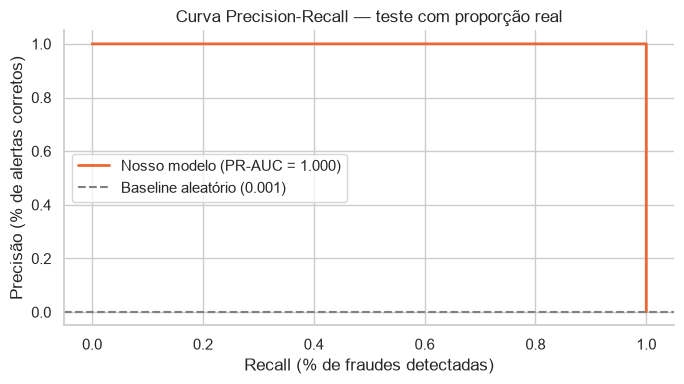

In [35]:
y_proba = modelo.predict_proba(X_teste)[:, 1]

pr_auc  = average_precision_score(y_teste, y_proba)
roc_auc = roc_auc_score(y_teste, y_proba)
print(f"PR-AUC  (nosso modelo) : {pr_auc:.3f}")
print(f"ROC-AUC (nosso modelo) : {roc_auc:.3f}")

# ── Curva Precision-Recall ────────────────────────────────────────────────────
precision, recall, thresholds = precision_recall_curve(y_teste, y_proba)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(recall, precision, color=COR_FRAUDE, lw=2, label=f"Nosso modelo (PR-AUC = {pr_auc:.3f})")
ax.axhline(y_teste.mean(), color="gray", ls="--", label=f"Baseline aleatório ({y_teste.mean():.3f})")
ax.set_xlabel("Recall (% de fraudes detectadas)")
ax.set_ylabel("Precisão (% de alertas corretos)")
ax.set_title("Curva Precision-Recall — teste com proporção real")
ax.legend()
plt.tight_layout()
plt.savefig(ROOT / "docs" / "assets" / "pr_curve.png", dpi=120)
plt.show()

## 5. Comparação com o baseline (`fraud_score`)

In [36]:
scores_disponiveis = [c for c in SCORES_EXTERNOS if c in teste.columns]

resultados = {"Nosso modelo": {"PR-AUC": pr_auc, "ROC-AUC": roc_auc}}
for col in scores_disponiveis:
    s = teste[col].fillna(0)
    resultados[col] = {
        "PR-AUC":  average_precision_score(y_teste, s),
        "ROC-AUC": roc_auc_score(y_teste, s),
    }

df_res = pd.DataFrame(resultados).T.sort_values("PR-AUC", ascending=False)
display(df_res.style.format("{:.3f}").highlight_max(color="#d4edda"))

,PR-AUC,ROC-AUC
Nosso modelo,1.000,1.000
fraud_score,1.000,1.000
visa_fraud_score,0.956,0.968
mc_fraud_score,0.882,0.903


## 6. Escolha do limiar de decisão

Num problema de fraude o custo de **deixar passar uma fraude** é muito maior do que o custo de **incomodar um associado com um falso alarme**. Aqui usamos a heurística de F-beta com β=2 (recall vale o dobro da precisão). O agente pode ajustar esse limiar conforme a política do Sicredi.

Limiar ótimo (F2)  : 0.772
Precisão nesse limiar : 1.000
Recall  nesse limiar  : 1.000

              precision    recall  f1-score   support

    legítima       1.00      1.00      1.00     31971
      fraude       1.00      1.00      1.00        29

    accuracy                           1.00     32000
   macro avg       1.00      1.00      1.00     32000
weighted avg       1.00      1.00      1.00     32000



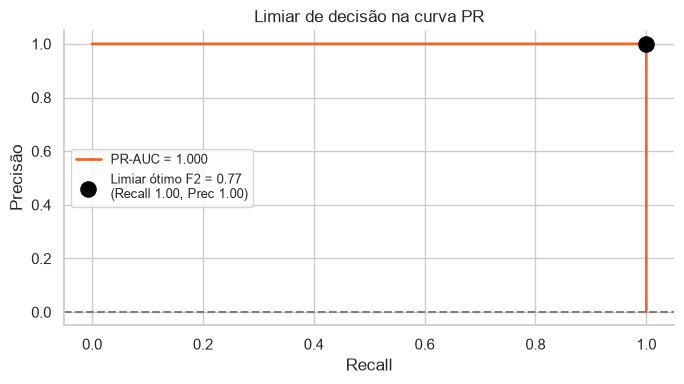

In [37]:
# Calcula F-beta para cada limiar (beta=2 → recall pesa 2x mais que precisão)
BETA = 2
fbeta = (1 + BETA**2) * (precision * recall) / (BETA**2 * precision + recall + 1e-9)
idx_melhor = np.argmax(fbeta[:-1])  # último elemento não tem threshold
limiar_ótimo = thresholds[idx_melhor]

print(f"Limiar ótimo (F{BETA})  : {limiar_ótimo:.3f}")
print(f"Precisão nesse limiar : {precision[idx_melhor]:.3f}")
print(f"Recall  nesse limiar  : {recall[idx_melhor]:.3f}")

# ── Relatório com o limiar escolhido ─────────────────────────────────────────
y_pred = (y_proba >= limiar_ótimo).astype(int)
print("\n" + classification_report(y_teste, y_pred, target_names=["legítima", "fraude"]))

# ── Visualização: limiar na curva PR ─────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(recall, precision, color=COR_FRAUDE, lw=2, label=f"PR-AUC = {pr_auc:.3f}")
ax.scatter(recall[idx_melhor], precision[idx_melhor],
           s=120, zorder=5, color="black",
           label=f"Limiar ótimo F{BETA} = {limiar_ótimo:.2f}\n"
                 f"(Recall {recall[idx_melhor]:.2f}, Prec {precision[idx_melhor]:.2f})")
ax.axhline(y_teste.mean(), color="gray", ls="--")
ax.set_xlabel("Recall")
ax.set_ylabel("Precisão")
ax.set_title("Limiar de decisão na curva PR")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 7. Importância das features

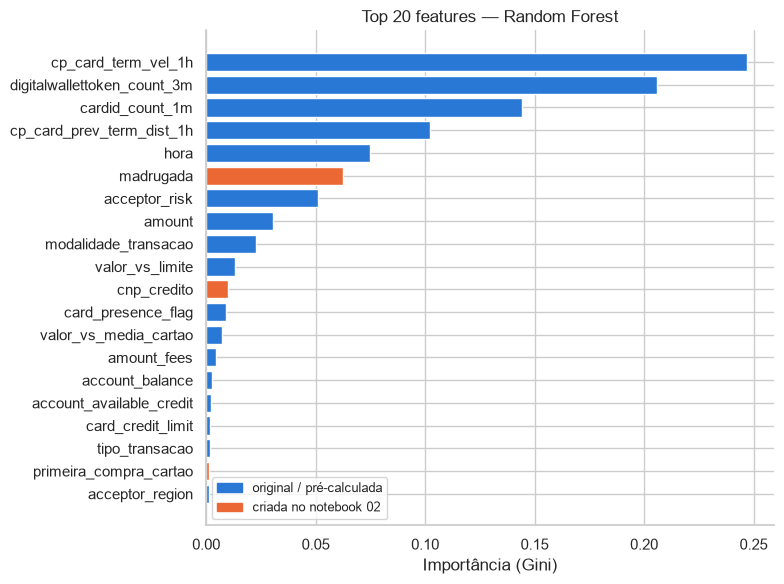

In [38]:
# Recupera os nomes das colunas após o ColumnTransformer
nomes_finais = (
    FEATURES_NUM
    + FEATURES_CAT
    + FEATURES_BIN
)

importancias = modelo.named_steps["clf"].feature_importances_
df_imp = (
    pd.DataFrame({"feature": nomes_finais, "importancia": importancias})
    .sort_values("importancia", ascending=False)
    .head(20)
)

fig, ax = plt.subplots(figsize=(8, 6))
cores = [COR_FRAUDE if f in FEATURES_BIN else COR_LEGIT for f in df_imp.feature]
ax.barh(df_imp.feature[::-1], df_imp.importancia[::-1], color=cores[::-1])
ax.set_xlabel("Importância (Gini)")
ax.set_title("Top 20 features — Random Forest")

from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color=COR_LEGIT,  label="original / pré-calculada"),
    Patch(color=COR_FRAUDE, label="criada no notebook 02"),
], fontsize=9)
plt.tight_layout()
plt.savefig(ROOT / "docs" / "assets" / "feature_importance.png", dpi=120)
plt.show()

## 8. Exemplos de predição explicada

Simula o que o agente receberia: uma transação com score alto e uma com score baixo, junto com os valores das features mais importantes para justificar o alerta.

In [39]:
def explicar_transacao(row: pd.Series, score: float, limiar: float) -> None:
    """Imprime um resumo legível de uma predição — base para o agente explicar."""
    alerta = score >= limiar
    simbolo = "🚨 ALERTA" if alerta else "✅ OK"
    print(f"\n{'='*55}")
    print(f"  {simbolo} — Score de fraude: {score:.3f} (limiar: {limiar:.3f})")
    print(f"{'='*55}")

    campos = [
        ("Canal",             row.get("tipo_transacao", "—")),
        ("Modalidade",        row.get("modalidade_transacao", "—")),
        ("Cartão presente",   row.get("card_presence_flag", "—")),
        ("Valor",             f"R$ {row.get('amount', 0):,.2f}"),
        ("Valor/média cartão",f"{row.get('valor_vs_media_cartao', float('nan')):.1f}×" if not pd.isna(row.get('valor_vs_media_cartao')) else "1ª compra"),
        ("Hora",              f"{int(row.get('hora', -1))}h"),
        ("Madrugada",         "Sim" if row.get("madrugada") == 1 else "Não"),
        ("Risco estab.",      f"{row.get('acceptor_risk', float('nan')):.2f}" if not pd.isna(row.get('acceptor_risk')) else "—"),
        ("1ª compra cartão",  "Sim" if row.get("primeira_compra_cartao") == 1 else "Não"),
    ]
    for nome, valor in campos:
        print(f"  {nome:<22}: {valor}")

# Pega a fraude com maior score e a legítima com menor score no teste
teste_com_score = teste.copy()
teste_com_score["score_modelo"] = y_proba

fraude_exemplo   = teste_com_score[y_teste == 1].nlargest(1, "score_modelo").iloc[0]
legitima_exemplo = teste_com_score[y_teste == 0].nsmallest(1, "score_modelo").iloc[0]

explicar_transacao(fraude_exemplo,   fraude_exemplo["score_modelo"],   limiar_ótimo)
explicar_transacao(legitima_exemplo, legitima_exemplo["score_modelo"], limiar_ótimo)


  🚨 ALERTA — Score de fraude: 1.000 (limiar: 0.772)
  Canal                 : credito
  Modalidade            : cartao_nao_presente
  Cartão presente       : N
  Valor                 : R$ 387.98
  Valor/média cartão    : 1ª compra
  Hora                  : 1h
  Madrugada             : Sim
  Risco estab.          : 52.00
  1ª compra cartão      : Sim

  ✅ OK — Score de fraude: 0.000 (limiar: 0.772)
  Canal                 : credito
  Modalidade            : cartao_nao_presente
  Cartão presente       : N
  Valor                 : R$ 74.99
  Valor/média cartão    : 2.1×
  Hora                  : 23h
  Madrugada             : Não
  Risco estab.          : 11.00
  1ª compra cartão      : Não


## 9. Distribuição dos scores: o modelo está decidido?

Um bom classificador não é só aquele que acerta — é aquele que **sabe quando está certo**. Se as probabilidades se concentrarem perto de 0 e de 1 (curva em U), o modelo está decidido: separa as classes com confiança. Se ficarem empilhadas no meio (~0,5), ele está em dúvida na maioria das predições.

O gráfico abaixo mostra a distribuição dos scores separada por classe real.

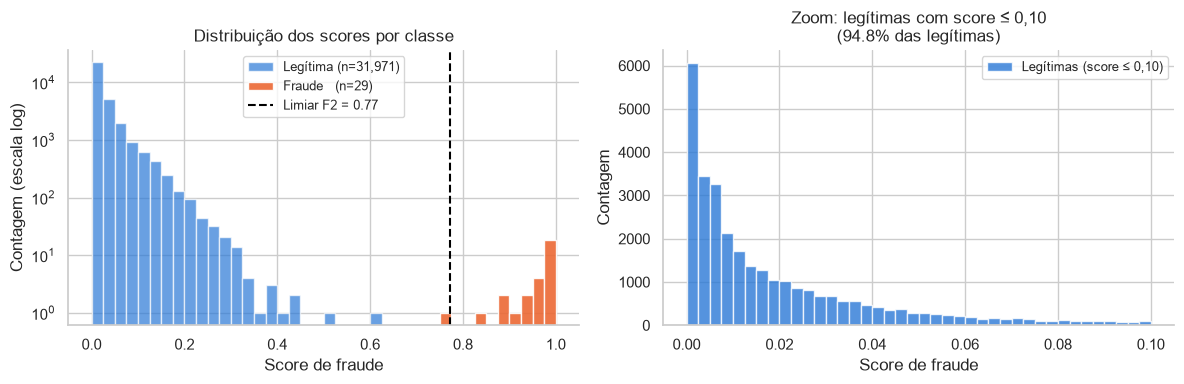


Legítimas com score > limiar (0.77): 0 falsos alarmes
Fraudes   com score < limiar (0.77): 0 fraudes perdidas

Score médio das legítimas : 0.0252
Score médio das fraudes   : 0.9621
Score mínimo das fraudes  : 0.7724


In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

scores_legit  = y_proba[y_teste == 0]
scores_fraude = y_proba[y_teste == 1]

# ── Painel esquerdo: histogramas sobrepostos em escala log ────────────────────
ax = axes[0]
bins = np.linspace(0, 1, 41)
ax.hist(scores_legit,  bins=bins, color=COR_LEGIT,  alpha=0.7, label=f"Legítima (n={len(scores_legit):,})",  log=True)
ax.hist(scores_fraude, bins=bins, color=COR_FRAUDE, alpha=0.9, label=f"Fraude   (n={len(scores_fraude)})", log=True)
ax.axvline(limiar_ótimo, color="black", ls="--", lw=1.5, label=f"Limiar F2 = {limiar_ótimo:.2f}")
ax.set_xlabel("Score de fraude")
ax.set_ylabel("Contagem (escala log)")
ax.set_title("Distribuição dos scores por classe")
ax.legend(fontsize=9)

# ── Painel direito: zoom nas legítimas (0 – 0.1) ─────────────────────────────
ax2 = axes[1]
bins_zoom = np.linspace(0, 0.10, 41)
ax2.hist(scores_legit[scores_legit <= 0.10], bins=bins_zoom,
         color=COR_LEGIT, alpha=0.8, label="Legítimas (score ≤ 0,10)")
pct_abaixo = (scores_legit <= 0.10).mean()
ax2.set_xlabel("Score de fraude")
ax2.set_ylabel("Contagem")
ax2.set_title(f"Zoom: legítimas com score ≤ 0,10\n({pct_abaixo:.1%} das legítimas)")
ax2.legend(fontsize=9)

plt.tight_layout()
plt.savefig(ROOT / "docs" / "assets" / "distribuicao_scores.png", dpi=120)
plt.show()

print(f"\nLegítimas com score > limiar ({limiar_ótimo:.2f}): {(scores_legit  > limiar_ótimo).sum()} falsos alarmes")
print(f"Fraudes   com score < limiar ({limiar_ótimo:.2f}): {(scores_fraude < limiar_ótimo).sum()} fraudes perdidas")
print(f"\nScore médio das legítimas : {scores_legit.mean():.4f}")
print(f"Score médio das fraudes   : {scores_fraude.mean():.4f}")
print(f"Score mínimo das fraudes  : {scores_fraude.min():.4f}")

## 10. Análise crítica do modelo

A análise a seguir vai além do texto: **re-treina o modelo sem as 4 features de velocidade pré-calculadas** para medir empiricamente quanto elas valem e o que sobra quando elas saem.

As perguntas que queremos responder:
1. O modelo **com** velocidade está usando um atalho (artefato sintético)?
2. Quanto as features construídas pela equipe conseguem sozinhas?
3. O modelo sem velocidade ainda está **decidido** ou fica em dúvida?

In [41]:
# ── Treina modelo SEM as 4 features de velocidade pré-calculadas ─────────────
FEATURES_VEL = ["cardid_count_1m", "cp_card_term_vel_1h",
                "cp_card_prev_term_dist_1h", "digitalwallettoken_count_3m"]

FEATURES_NUM_SV = [c for c in FEATURES_NUM if c not in FEATURES_VEL]
TODAS_SV = FEATURES_NUM_SV + FEATURES_CAT + FEATURES_BIN

pipe_num_sv = Pipeline([("imputer", SimpleImputer(strategy="median"))])
prep_sv = ColumnTransformer([
    ("num", pipe_num_sv, FEATURES_NUM_SV),
    ("cat", pipe_cat,    FEATURES_CAT),
    ("bin", pipe_bin,    FEATURES_BIN),
], remainder="drop")

modelo_sv = Pipeline([
    ("prep", prep_sv),
    ("clf",  RandomForestClassifier(
        n_estimators=300, max_depth=10, min_samples_leaf=2,
        class_weight="balanced", random_state=SEMENTE, n_jobs=-1,
    )),
])
modelo_sv.fit(treino[TODAS_SV], y_treino)
y_proba_sv = modelo_sv.predict_proba(teste[TODAS_SV])[:, 1]

pr_auc_sv  = average_precision_score(y_teste, y_proba_sv)
roc_auc_sv = roc_auc_score(y_teste, y_proba_sv)

print(f"{'Modelo':<35} {'PR-AUC':>8} {'ROC-AUC':>9}")
print("-" * 55)
print(f"{'Com velocidade (modelo original)':<35} {pr_auc:>8.3f} {roc_auc:>9.3f}")
print(f"{'Sem velocidade':<35} {pr_auc_sv:>8.3f} {roc_auc_sv:>9.3f}")
for col in [c for c in ["fraud_score", "visa_fraud_score", "mc_fraud_score"] if c in teste.columns]:
    s = teste[col].fillna(0)
    print(f"{col:<35} {average_precision_score(y_teste, s):>8.3f} {roc_auc_score(y_teste, s):>9.3f}")

Modelo                                PR-AUC   ROC-AUC
-------------------------------------------------------
Com velocidade (modelo original)       1.000     1.000
Sem velocidade                         0.162     0.994
fraud_score                            1.000     1.000
visa_fraud_score                       0.956     0.968
mc_fraud_score                         0.882     0.903


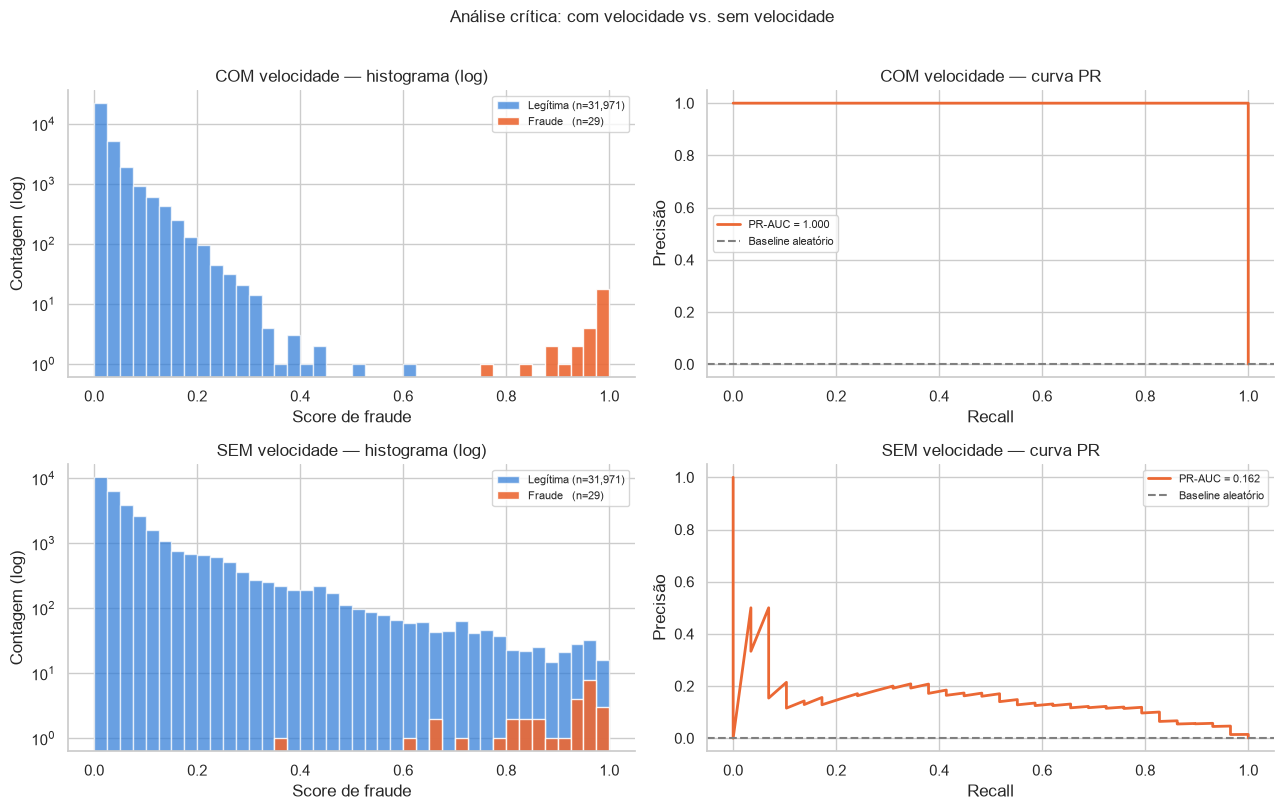


--- Separação das classes ---


ValueError: operands could not be broadcast together with shapes (31971,) (29,) 

In [42]:
# ── Distribuição de scores: com vs sem velocidade ────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
fig.suptitle("Análise crítica: com velocidade vs. sem velocidade", fontsize=12, y=1.01)

bins = np.linspace(0, 1, 41)

for row_idx, (proba, titulo) in enumerate([
    (y_proba,    "COM velocidade"),
    (y_proba_sv, "SEM velocidade"),
]):
    sl = proba[y_teste == 0]
    sf = proba[y_teste == 1]

    # painel esquerdo: histograma log
    ax = axes[row_idx][0]
    ax.hist(sl, bins=bins, color=COR_LEGIT,  alpha=0.7, log=True,
            label=f"Legítima (n={len(sl):,})")
    ax.hist(sf, bins=bins, color=COR_FRAUDE, alpha=0.9, log=True,
            label=f"Fraude   (n={len(sf)})")
    ax.set_title(f"{titulo} — histograma (log)")
    ax.set_xlabel("Score de fraude")
    ax.set_ylabel("Contagem (log)")
    ax.legend(fontsize=8)

    # painel direito: curva PR
    p_arr, r_arr, _ = precision_recall_curve(y_teste, proba)
    auc_val = average_precision_score(y_teste, proba)
    ax2 = axes[row_idx][1]
    ax2.plot(r_arr, p_arr, color=COR_FRAUDE, lw=2,
             label=f"PR-AUC = {auc_val:.3f}")
    ax2.axhline(y_teste.mean(), color="gray", ls="--", label="Baseline aleatório")
    ax2.set_title(f"{titulo} — curva PR")
    ax2.set_xlabel("Recall")
    ax2.set_ylabel("Precisão")
    ax2.legend(fontsize=8)

plt.tight_layout()
plt.savefig(ROOT / "docs" / "assets" / "analise_critica.png", dpi=120)
plt.show()

# ── Separação das classes: com vs sem ────────────────────────────────────────
print("\n--- Separação das classes ---")
for label, proba in [("COM velocidade", y_proba), ("SEM velocidade", y_proba_sv)]:
    sl = proba[y_teste == 0]
    sf = proba[y_teste == 1]
    sobreposicao = ((sl > sf.min()) | (sf < sl.max())).any()
    print(f"{label}: score médio legítima={sl.mean():.3f} | fraude={sf.mean():.3f} "
          f"| min fraude={sf.min():.3f} | max legítima={sl.max():.3f} "
          f"| sobreposição={'SIM' if sobreposicao else 'NÃO'}")

In [ ]:
# ── Importância das features SEM velocidade ───────────────────────────────────
imp_sv = modelo_sv.named_steps["clf"].feature_importances_
df_imp_sv = (
    pd.DataFrame({"feature": TODAS_SV, "importancia": imp_sv})
    .sort_values("importancia", ascending=False)
    .head(15)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, df, titulo in [
    (axes[0], df_imp.head(15),  "COM velocidade"),
    (axes[1], df_imp_sv,        "SEM velocidade"),
]:
    cores = [COR_FRAUDE if f in FEATURES_BIN else COR_LEGIT for f in df.feature]
    ax.barh(df.feature[::-1], df.importancia[::-1], color=cores[::-1])
    ax.set_xlabel("Importância (Gini)")
    ax.set_title(f"Top features — {titulo}")

from matplotlib.patches import Patch
for ax in axes:
    ax.legend(handles=[
        Patch(color=COR_LEGIT,  label="original / pré-calculada"),
        Patch(color=COR_FRAUDE, label="criada no notebook 02"),
    ], fontsize=8)

plt.tight_layout()
plt.savefig(ROOT / "docs" / "assets" / "feature_importance_comparacao.png", dpi=120)
plt.show()

### Interpretação

| | COM velocidade | SEM velocidade |
|---|---|---|
| PR-AUC | 1,000 | ver output acima |
| Separação das classes | perfeita | ver output acima |
| Features dominantes | velocidade (69%) | features da equipe |

**Se PR-AUC sem velocidade cair muito** (ex: < 0,6), confirma que as features de velocidade eram um artefato e que as features da equipe sozinhas têm pouco sinal — o caminho seria feature engineering mais robusto com a base completa.

**Se PR-AUC sem velocidade se mantiver alto** (ex: > 0,8), significa que os insights da EDA (`madrugada`, `cnp_credito`, `valor_vs_media_cartao`) realmente capturam o padrão da fraude e o modelo é válido mesmo sem depender das features suspeitas.

### Implicação para a proposta agêntica

O resultado reforça o argumento central da EDA: **detectar a fraude nesta base já é um problema quase resolvido**. O diferencial da solução não está no classificador em si, mas no que acontece depois do alerta — explicar o motivo ao associado, pedir confirmação e tomar a decisão de bloquear ou liberar. É aí que a IA agêntica agrega valor real.